In [59]:
import os

DATASET = "/kaggle/input"

for root, dirs, files in os.walk(DATASET):
    tiffs = [f for f in files if f.lower().endswith(".tiff")]

    if len(tiffs) > 0:
        print("\nFolder:", root)
        print("TIFF Count:", len(tiffs))
        print("First 10 Files:")
        for f in sorted(tiffs)[:10]:
            print("   ", f)
        print("-"*80)


Folder: /kaggle/input/datasets/brycehopkins/flame-3-nadir-thermal-plot-subset/Hanna Hammock/plot 1/duringburn/geo_thermal_tiff_celsius
TIFF Count: 296
First 10 Files:
    IRX_0529_ref_geo.TIFF
    IRX_0530_ref_geo.TIFF
    IRX_0531_ref_geo.TIFF
    IRX_0532_ref_geo.TIFF
    IRX_0533_ref_geo.TIFF
    IRX_0534_ref_geo.TIFF
    IRX_0535_ref_geo.TIFF
    IRX_0536_ref_geo.TIFF
    IRX_0537_ref_geo.TIFF
    IRX_0538_ref_geo.TIFF
--------------------------------------------------------------------------------

Folder: /kaggle/input/datasets/brycehopkins/flame-3-nadir-thermal-plot-subset/Hanna Hammock/plot 1/duringburn/raw_thermal_tiff
TIFF Count: 297
First 10 Files:
    IRX_0528.TIFF
    IRX_0529.TIFF
    IRX_0530.TIFF
    IRX_0531.TIFF
    IRX_0532.TIFF
    IRX_0533.TIFF
    IRX_0534.TIFF
    IRX_0535.TIFF
    IRX_0536.TIFF
    IRX_0537.TIFF
--------------------------------------------------------------------------------

Folder: /kaggle/input/datasets/brycehopkins/flame-3-nadir-thermal-plo

In [60]:
!pip -q install segmentation-models-pytorch rasterio tifffile opencv-python

In [61]:
import os
import glob
import cv2
import random
import rasterio
import tifffile
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import segmentation_models_pytorch as smp

from tqdm import tqdm

In [62]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device :", device)

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

Device : cuda
GPU : Tesla T4


In [63]:
thermal_files = sorted(
    glob.glob(
        "/kaggle/input/**/*.TIFF",
        recursive=True
    )
)

thermal_files = [
    f for f in thermal_files
    if "geo_thermal_tiff_celsius" in f
]

print("Total Thermal Images :", len(thermal_files))
print(thermal_files[0])

Total Thermal Images : 794
/kaggle/input/datasets/brycehopkins/flame-3-nadir-thermal-plot-subset/Hanna Hammock/plot 1/duringburn/geo_thermal_tiff_celsius/IRX_0529_ref_geo.TIFF


In [64]:
UNET_PATH = None

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file == "unet_fire_segmentation_final.pth":
            UNET_PATH = os.path.join(root, file)

print("UNET_PATH")
print(UNET_PATH)

UNET_PATH
/kaggle/input/datasets/nithinbr2005/unet-fire-segmentation-fina-4/unet_fire_segmentation_final.pth


In [65]:
unet = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1
)

In [66]:
checkpoint = torch.load(
    UNET_PATH,
    map_location=device
)

unet.load_state_dict(
    checkpoint["model_state_dict"]
)

threshold = checkpoint["threshold"]

unet = unet.to(device)
unet.eval()

print("Loaded Successfully")
print("Threshold :", threshold)

Loaded Successfully
Threshold : 0.3


In [67]:
def preprocess(path):

    with rasterio.open(path) as src:
        img = src.read(1)

    img = np.nan_to_num(img)

    img = (img - img.min()) / (img.max() - img.min() + 1e-8)

    img = (img * 255).astype(np.uint8)

    img = cv2.resize(img, (256,256))

    rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

    tensor = torch.from_numpy(
        rgb.astype(np.float32)/255.0
    ).permute(2,0,1).unsqueeze(0)

    return img, tensor

In [68]:
fire_masks = []

for path in tqdm(thermal_files):

    image, tensor = preprocess(path)

    tensor = tensor.to(device)

    with torch.no_grad():

        pred = unet(tensor)

        pred = torch.sigmoid(pred)

        mask = (pred > threshold).float()

    fire_masks.append(mask.squeeze().cpu().numpy())

print("Generated Masks :", len(fire_masks))

100%|██████████| 794/794 [00:25<00:00, 31.22it/s]

Generated Masks : 794


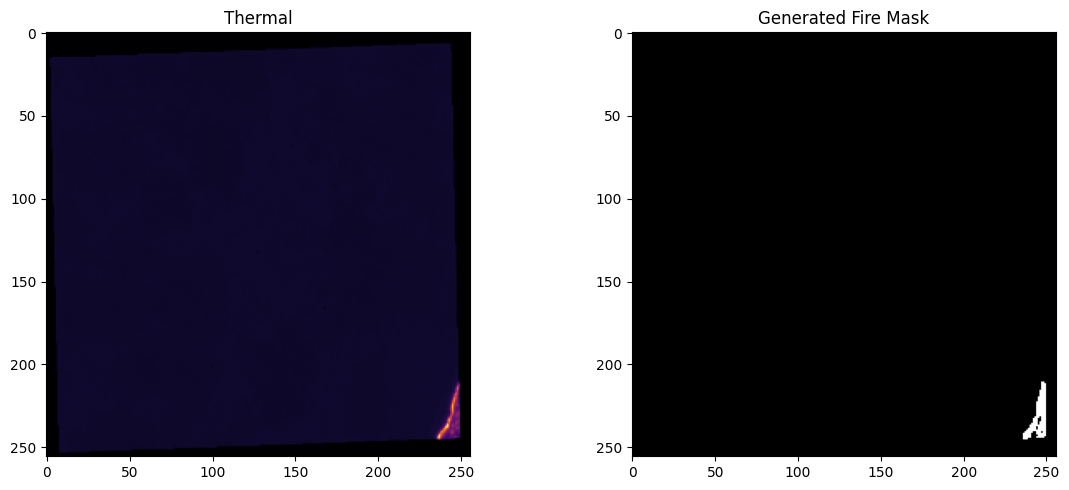

In [69]:
idx = random.randint(0, len(fire_masks)-1)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(preprocess(thermal_files[idx])[0], cmap="inferno")
plt.title("Thermal")

plt.subplot(1,2,2)
plt.imshow(fire_masks[idx], cmap="gray")
plt.title("Generated Fire Mask")

plt.tight_layout()
plt.show()

In [82]:
from collections import defaultdict
import os

sequence_groups = defaultdict(list)

for path, mask in zip(thermal_files, fire_masks):

    folder = os.path.dirname(path)

    sequence_groups[folder].append(mask)

print("Total Sequences:", len(sequence_groups))

for folder in sequence_groups:
    print(folder, len(sequence_groups[folder]))

Total Sequences: 3
/kaggle/input/datasets/brycehopkins/flame-3-nadir-thermal-plot-subset/Hanna Hammock/plot 1/duringburn/geo_thermal_tiff_celsius 296
/kaggle/input/datasets/brycehopkins/flame-3-nadir-thermal-plot-subset/Hanna Hammock/plot 2/duringburn/geo_thermal_tiff_celsius/part1 322
/kaggle/input/datasets/brycehopkins/flame-3-nadir-thermal-plot-subset/Hanna Hammock/plot 2/duringburn/geo_thermal_tiff_celsius/part2 176


In [83]:
SEQUENCE_LENGTH = 5

X = []
Y = []

for folder in sequence_groups:

    masks = sequence_groups[folder]

    for i in range(len(masks)-SEQUENCE_LENGTH):

        X.append(masks[i:i+SEQUENCE_LENGTH])

        Y.append(masks[i+SEQUENCE_LENGTH])

X = np.array(X,dtype=np.float32)
Y = np.array(Y,dtype=np.float32)

print(X.shape)
print(Y.shape)

(779, 5, 256, 256)
(779, 256, 256)


In [87]:
# Cell 13

class FireSequenceDataset(Dataset):

    def __init__(self, X, Y):
        self.X = X
        self.Y = Y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):

        sequence = torch.tensor(self.X[idx], dtype=torch.float32)

        target = torch.tensor(self.Y[idx], dtype=torch.float32)

        sequence = sequence.unsqueeze(1)      # (5,1,256,256)
        target = target.unsqueeze(0)          # (1,256,256)

        return sequence, target

In [88]:
# Cell 14

train_dataset = FireSequenceDataset(
    X_train,
    Y_train
)

val_dataset = FireSequenceDataset(
    X_val,
    Y_val
)

print("Train Dataset :", len(train_dataset))
print("Validation Dataset :", len(val_dataset))

Train Dataset : 631
Validation Dataset : 158


In [89]:
# Cell 15

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train Batches :", len(train_loader))
print("Validation Batches :", len(val_loader))

Train Batches : 158
Validation Batches : 40


In [90]:
# Cell 16

sequence, target = next(iter(train_loader))

print("Sequence Shape :", sequence.shape)
print("Target Shape   :", target.shape)

Sequence Shape : torch.Size([4, 5, 1, 256, 256])
Target Shape   : torch.Size([4, 1, 256, 256])


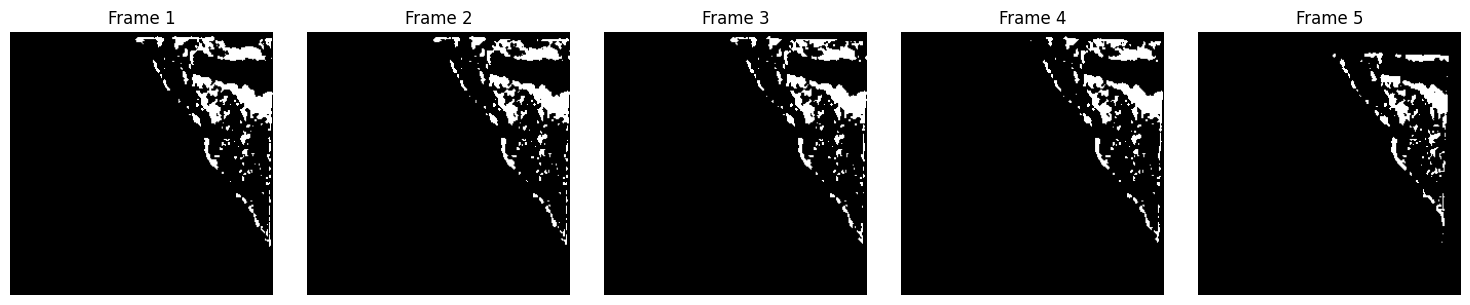

In [91]:
# Cell 17

sample_sequence = sequence[0]

plt.figure(figsize=(15,3))

for i in range(SEQUENCE_LENGTH):

    plt.subplot(1, SEQUENCE_LENGTH, i + 1)

    plt.imshow(sample_sequence[i,0], cmap="gray")

    plt.title(f"Frame {i+1}")

    plt.axis("off")

plt.tight_layout()

plt.show()

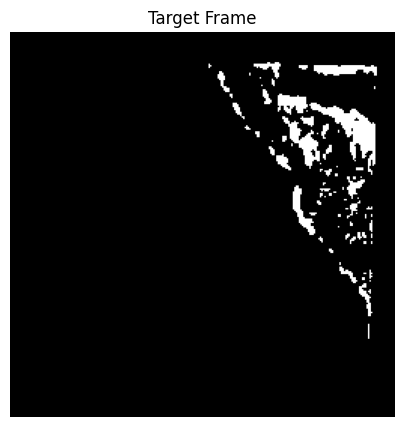

In [92]:
# Cell 18

plt.figure(figsize=(5,5))

plt.imshow(target[0,0], cmap="gray")

plt.title("Target Frame")

plt.axis("off")

plt.show()

In [93]:
# Cell 19

print("Sequence Length :", sample_sequence.shape[0])

print("Frames Used")

for i in range(SEQUENCE_LENGTH):
    print("Frame", i+1)

print("Target = Next Frame")

Sequence Length : 5
Frames Used
Frame 1
Frame 2
Frame 3
Frame 4
Frame 5
Target = Next Frame


In [94]:
# Cell 20

import gc

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Memory Cleared")

Memory Cleared


In [95]:
from collections import defaultdict
import os

groups = defaultdict(list)

for path in thermal_files:
    folder = os.path.dirname(path)
    groups[folder].append(path)

print("Total sequences:", len(groups))

for folder, files in list(groups.items())[:10]:
    print(folder)
    print("Frames:", len(files))
    print("First:", os.path.basename(sorted(files)[0]))
    print("Last :", os.path.basename(sorted(files)[-1]))
    print("-" * 60)

Total sequences: 3
/kaggle/input/datasets/brycehopkins/flame-3-nadir-thermal-plot-subset/Hanna Hammock/plot 1/duringburn/geo_thermal_tiff_celsius
Frames: 296
First: IRX_0529_ref_geo.TIFF
Last : IRX_0824_ref_geo.TIFF
------------------------------------------------------------
/kaggle/input/datasets/brycehopkins/flame-3-nadir-thermal-plot-subset/Hanna Hammock/plot 2/duringburn/geo_thermal_tiff_celsius/part1
Frames: 322
First: IRX_0826_ref_geo.TIFF
Last : IRX_1147_ref_geo.TIFF
------------------------------------------------------------
/kaggle/input/datasets/brycehopkins/flame-3-nadir-thermal-plot-subset/Hanna Hammock/plot 2/duringburn/geo_thermal_tiff_celsius/part2
Frames: 176
First: IRX_1171_ref_geo.TIFF
Last : IRX_1346_ref_geo.TIFF
------------------------------------------------------------


In [106]:
class ConvLSTMCell(nn.Module):

    def __init__(self, input_channels, hidden_channels, kernel_size=3):

        super().__init__()

        padding = kernel_size // 2

        self.hidden_channels = hidden_channels

        self.conv = nn.Conv2d(
            input_channels + hidden_channels,
            4 * hidden_channels,
            kernel_size,
            padding=padding
        )

    def forward(self, x, h, c):

        combined = torch.cat([x, h], dim=1)

        gates = self.conv(combined)

        i, f, o, g = torch.chunk(gates, 4, dim=1)

        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        o = torch.sigmoid(o)
        g = torch.tanh(g)

        c = f * c + i * g
        h = o * torch.tanh(c)

        return h, c

In [107]:
class ConvLSTM(nn.Module):

    def __init__(self):

        super().__init__()

        self.hidden_channels = 32

        self.cell = ConvLSTMCell(
            input_channels=1,
            hidden_channels=self.hidden_channels
        )

        self.output = nn.Conv2d(
            self.hidden_channels,
            1,
            kernel_size=1
        )

    def forward(self, x):

        batch, seq_len, ch, h, w = x.size()

        hidden = torch.zeros(
            batch,
            self.hidden_channels,
            h,
            w,
            device=x.device
        )

        cell = torch.zeros_like(hidden)

        for t in range(seq_len):

            hidden, cell = self.cell(
                x[:, t],
                hidden,
                cell
            )

        out = self.output(hidden)

        return out

In [108]:
model = ConvLSTM().to(device)

print(model)

ConvLSTM(
  (cell): ConvLSTMCell(
    (conv): Conv2d(33, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (output): Conv2d(32, 1, kernel_size=(1, 1), stride=(1, 1))
)


In [111]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

In [113]:
def dice_score(pred, target):

    pred = torch.sigmoid(pred)

    pred = (pred > 0.5).float()

    intersection = (pred * target).sum()

    return (
        2 * intersection + 1e-8
    ) / (
        pred.sum() +
        target.sum() +
        1e-8
    )

In [114]:
def train_epoch():

    model.train()

    total_loss = 0

    total_dice = 0

    for sequence, target in train_loader:

        sequence = sequence.to(device)

        target = target.to(device)

        optimizer.zero_grad()

        output = model(sequence)

        loss = criterion(output, target)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        total_dice += dice_score(
            output,
            target
        ).item()

    return (
        total_loss / len(train_loader),
        total_dice / len(train_loader)
    )

In [115]:
def validate():

    model.eval()

    total_loss = 0

    total_dice = 0

    with torch.no_grad():

        for sequence, target in val_loader:

            sequence = sequence.to(device)

            target = target.to(device)

            output = model(sequence)

            loss = criterion(output, target)

            total_loss += loss.item()

            total_dice += dice_score(
                output,
                target
            ).item()

    return (
        total_loss / len(val_loader),
        total_dice / len(val_loader)
    )

In [116]:
EPOCHS = 20

best_dice = 0

history = []

for epoch in range(EPOCHS):

    train_loss, train_dice = train_epoch()

    val_loss, val_dice = validate()

    history.append([
        train_loss,
        val_loss,
        train_dice,
        val_dice
    ])

    print(
        f"Epoch {epoch+1}/{EPOCHS}"
    )

    print(
        f"Train Loss : {train_loss:.4f}"
    )

    print(
        f"Val Loss   : {val_loss:.4f}"
    )

    print(
        f"Train Dice : {train_dice:.4f}"
    )

    print(
        f"Val Dice   : {val_dice:.4f}"
    )

    if val_dice > best_dice:

        best_dice = val_dice

        torch.save(
            model.state_dict(),
            "future_fire_prediction.pth"
        )

        print("Best Model Saved")

Epoch 1/20
Train Loss : 0.1194
Val Loss   : 0.0558
Train Dice : 0.6383
Val Dice   : 0.6071
Best Model Saved
Epoch 2/20
Train Loss : 0.0285
Val Loss   : 0.0402
Train Dice : 0.7537
Val Dice   : 0.7161
Best Model Saved
Epoch 3/20
Train Loss : 0.0213
Val Loss   : 0.0350
Train Dice : 0.8135
Val Dice   : 0.7413
Best Model Saved
Epoch 4/20
Train Loss : 0.0186
Val Loss   : 0.0321
Train Dice : 0.8304
Val Dice   : 0.7585
Best Model Saved
Epoch 5/20
Train Loss : 0.0169
Val Loss   : 0.0311
Train Dice : 0.8399
Val Dice   : 0.7635
Best Model Saved
Epoch 6/20
Train Loss : 0.0160
Val Loss   : 0.0296
Train Dice : 0.8466
Val Dice   : 0.7765
Best Model Saved
Epoch 7/20
Train Loss : 0.0154
Val Loss   : 0.0298
Train Dice : 0.8518
Val Dice   : 0.7890
Best Model Saved
Epoch 8/20
Train Loss : 0.0151
Val Loss   : 0.0290
Train Dice : 0.8553
Val Dice   : 0.7807
Epoch 9/20
Train Loss : 0.0147
Val Loss   : 0.0285
Train Dice : 0.8577
Val Dice   : 0.7963
Best Model Saved
Epoch 10/20
Train Loss : 0.0145
Val Loss   : 

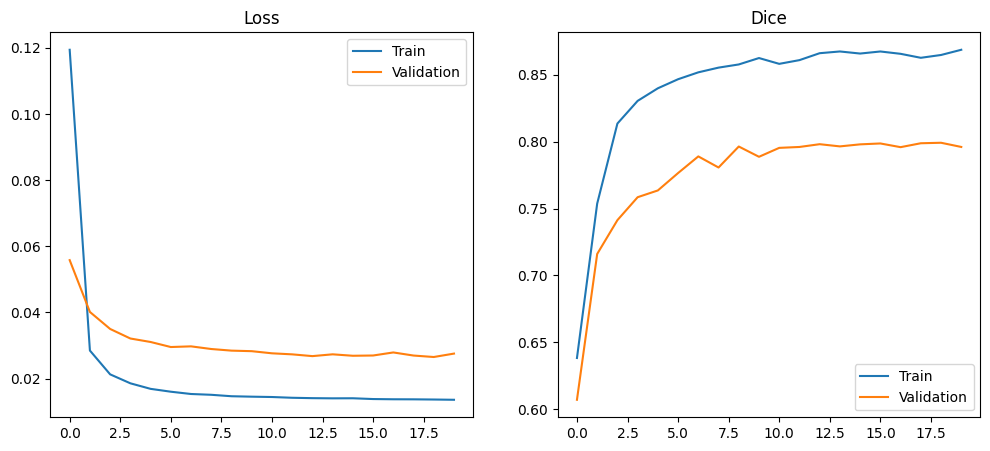

In [124]:
history = np.array(history)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history[:,0], label="Train")
plt.plot(history[:,1], label="Validation")
plt.title("Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history[:,2], label="Train")
plt.plot(history[:,3], label="Validation")
plt.title("Dice")
plt.legend()

plt.show()

In [125]:
import os

print("Saved:", os.path.exists("future_fire_prediction.pth"))

Saved: True


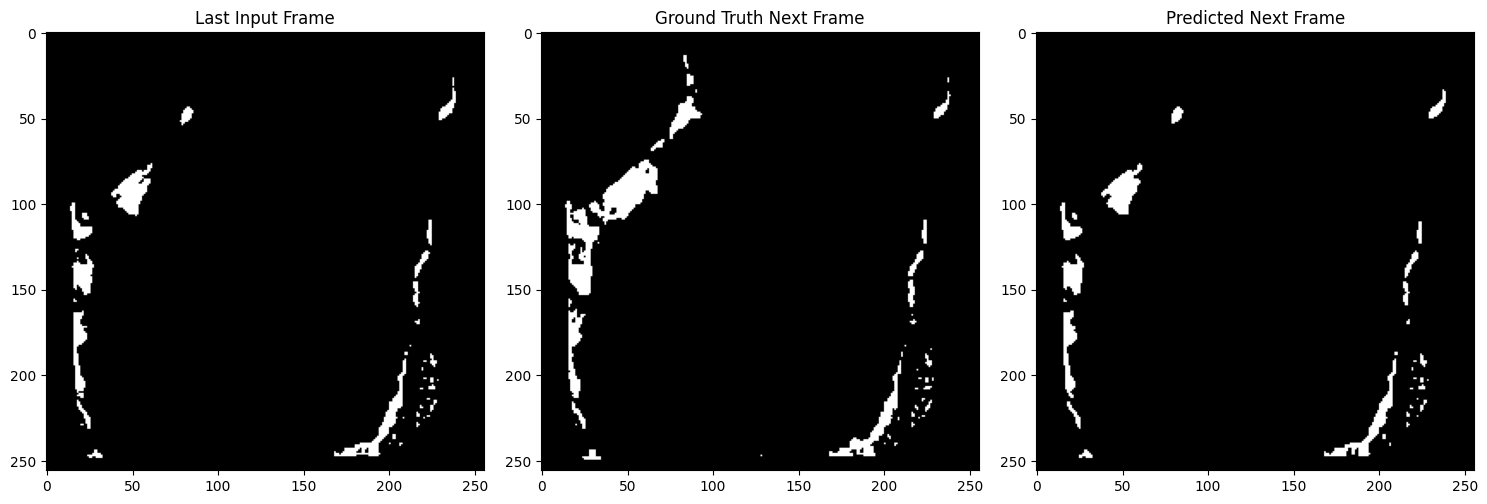

In [126]:
model.eval()

sequence, target = next(iter(val_loader))

sequence = sequence.to(device)
target = target.to(device)

with torch.no_grad():
    prediction = model(sequence)
    prediction = torch.sigmoid(prediction)
    prediction = (prediction > 0.5).float()

current = sequence[0, -1, 0].cpu().numpy()
ground_truth = target[0, 0].cpu().numpy()
predicted = prediction[0, 0].cpu().numpy()

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(current, cmap="gray")
plt.title("Last Input Frame")

plt.subplot(1,3,2)
plt.imshow(ground_truth, cmap="gray")
plt.title("Ground Truth Next Frame")

plt.subplot(1,3,3)
plt.imshow(predicted, cmap="gray")
plt.title("Predicted Next Frame")

plt.tight_layout()
plt.show()

Different Pixels: 1088.0


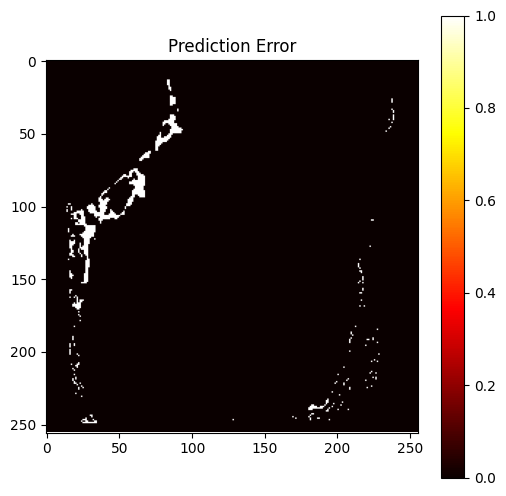

In [127]:
difference = np.abs(predicted - ground_truth)

print("Different Pixels:", np.sum(difference))

plt.figure(figsize=(6,6))
plt.imshow(difference, cmap="hot")
plt.title("Prediction Error")
plt.colorbar()
plt.show()

In [128]:
torch.save(model.state_dict(), "future_fire_prediction.pth")

print("Saved Successfully")

Saved Successfully


In [129]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "sequence_length": SEQUENCE_LENGTH,
        "hidden_channels": 32,
        "val_dice": best_dice,
        "epochs": EPOCHS
    },
    "future_fire_prediction.pth"
)

print("Model Saved Successfully")

Model Saved Successfully
